# Задача 3. AVL

**Условие.** Реализовать класс `AVL` — самобалансирующееся бинарное дерево поиска с операциями вставки, удаления и поиска.

**Путь для сдачи:** `/homework_5/AVL/`.


# Ход решения

Реализуем **AVL-дерево** — бинарное дерево поиска, которое поддерживает баланс после вставки и удаления. В обычном BST все значения слева от узла меньше его значения, а справа — больше. Поэтому при поиске, вставке и удалении достаточно сравнивать значение с текущим узлом и переходить только в одно поддерево. Но обычное BST может превратиться в длинную цепочку, если добавлять элементы по порядку. AVL не допускает такого случая благодаря балансировке.

В каждом узле будем хранить `value`, ссылки `left` и `right`, а также `height` — высоту поддерева с корнем в этом узле. Высота пустого дерева равна `0`, листа — `1`. Для проверки баланса считаем разницу высот левого и правого поддеревьев: `balance = height(left) - height(right)`. В AVL для каждого узла она должна быть равна `-1`, `0` или `1`.

**Вставка.** Сначала рекурсивно ищем место для нового значения, как в обычном BST: если значение меньше текущего, идём налево, если больше — направо. Когда дошли до `None`, создаём узел. Затем на **обратном пути рекурсии** пересчитываем высоты и проверяем баланс. Если одно поддерево стало слишком высоким, выполняем поворот. Есть четыре случая: LL и RR исправляются одним поворотом, а LR и RL — двумя последовательными поворотами. Повороты меняют связи между узлами, но сохраняют порядок значений BST.

**Удаление.** Сначала рекурсивно находим нужный узел. Если у него нет детей, удаляем его; если один ребёнок — возвращаем этого ребёнка вместо удалённого узла. Если детей два, находим минимальный элемент в правом поддереве (следующий по величине), переносим его значение в удаляемый узел и удаляем найденный элемент из правого поддерева. После изменения дерева при возвращении из рекурсии снова обновляем высоты и выполняем повороты при необходимости. Для вставки и удаления используется одна функция `_rebalance`.

**Поиск.** Начинаем с корня и сравниваем искомое значение с текущим. Если оно меньше, идём влево, иначе вправо. Если нашли равное значение, возвращаем `True`, если дошли до `None` — `False`. Баланс дерева при поиске не меняется.

Важно, что после поворота **корень поддерева может измениться**, поэтому рекурсивные функции `_insert` и `_delete` возвращают корень обновлённого поддерева, а публичные `insert` и `delete` сохраняют его в `self.root`. Благодаря проверке баланса при возвращении вверх дерево остаётся AVL после каждой операции.

# Граничные случаи

- В пустое дерево можно вставить первый элемент; поиск в пустом дереве возвращает `False`, а удаление ничего не меняет.
- Если удалить лист или узел с одним ребёнком, не нужно искать замену в другом поддереве.
- Если удалить узел с двумя детьми, используем минимум правого поддерева.
- Если значения нет в дереве, удаление ничего не меняет.
- **Повторяющиеся значения не вставляем**: в этой реализации каждый ключ хранится один раз.
- Отрицательные числа и `0` обрабатываются так же, как положительные.

# Сложность алгоритма

Пусть `n` — число узлов, а `h` — высота дерева. Благодаря балансировке AVL имеет высоту `h = O(log n)`.

- **Поиск:** `O(log n)` по времени, `O(1)` дополнительной памяти, поскольку используем цикл.
- **Вставка:** `O(log n)` по времени и `O(log n)` памяти на стек рекурсии.
- **Удаление:** `O(log n)` по времени и `O(log n)` памяти на стек рекурсии, включая поиск замены для узла с двумя детьми.
- Каждый поворот выполняется за `O(1)`: меняются только несколько ссылок и высот. Все узлы дерева занимают `O(n)` памяти.


# Реализация алгоритма

In [1]:
class Node:
    def __init__(self, value):
        self.value = value
        self.left = None
        self.right = None
        self.height = 1


class AVL:
    def __init__(self):
        self.root = None

    def _height(self, node):
        return node.height if node else 0

    def _update_height(self, node):
        node.height = 1 + max(self._height(node.left), self._height(node.right))

    def _balance(self, node):
        return self._height(node.left) - self._height(node.right)

    def _rotate_left(self, node):
        new_root = node.right
        node.right = new_root.left
        new_root.left = node
        self._update_height(node)
        self._update_height(new_root)
        return new_root

    def _rotate_right(self, node):
        new_root = node.left
        node.left = new_root.right
        new_root.right = node
        self._update_height(node)
        self._update_height(new_root)
        return new_root

    def _rebalance(self, node):
        self._update_height(node)
        balance = self._balance(node)

        if balance > 1:
            if self._balance(node.left) < 0:
                node.left = self._rotate_left(node.left)
            return self._rotate_right(node)

        if balance < -1:
            if self._balance(node.right) > 0:
                node.right = self._rotate_right(node.right)
            return self._rotate_left(node)

        return node

    def insert(self, value):
        self.root = self._insert(self.root, value)

    def _insert(self, node, value):
        if node is None:
            return Node(value)

        if value < node.value:
            node.left = self._insert(node.left, value)
        elif value > node.value:
            node.right = self._insert(node.right, value)
        else:
            return node

        return self._rebalance(node)

    def delete(self, value):
        self.root = self._delete(self.root, value)

    def _delete(self, node, value):
        if node is None:
            return None

        if value < node.value:
            node.left = self._delete(node.left, value)
        elif value > node.value:
            node.right = self._delete(node.right, value)
        else:
            if node.left is None:
                return node.right
            if node.right is None:
                return node.left

            successor = node.right
            while successor.left:
                successor = successor.left

            node.value = successor.value
            node.right = self._delete(node.right, successor.value)

        return self._rebalance(node)

    def search(self, value):
        node = self.root
        while node:
            if value == node.value:
                return True
            node = node.left if value < node.value else node.right
        return False


# Проверка на нетривиальном примере

In [2]:
tree = AVL()
for value in [30, 20, 40, 10, 25]:
    tree.insert(value)

print('Поиск 25:', tree.search(25))
print('Поиск 100:', tree.search(100))

tree.delete(40)
print('Корень после удаления 40:', tree.root.value)
print('Поиск 40 после удаления:', tree.search(40))


Поиск 25: True
Поиск 100: False
Корень после удаления 40: 20
Поиск 40 после удаления: False


# Визуализация работы алгоритма

**1. Вставка и четыре случая поворотов.** В каждом случае добавляем по три значения. После балансировки получаем одно и то же дерево с корнем `20`.

| Случай | Порядок вставки | Исправление |
| --- | --- | --- |
| LL | `30, 20, 10` | Правый поворот вокруг `30` |
| RR | `10, 20, 30` | Левый поворот вокруг `10` |
| LR | `30, 10, 20` | Левый поворот вокруг `10`, затем правый вокруг `30` |
| RL | `10, 30, 20` | Правый поворот вокруг `30`, затем левый вокруг `10` |

Например, при вставке `30, 10, 20` возникает случай **LR**:

```text
     30               30                20
    /                /                 /  \
   10      →        20       →        10  30
     \             /
      20          10

     После вставки   После левого     После правого
         20           поворота          поворота
```

**2. Удаление и восстановление баланса.** Вставим `30, 20, 40, 10, 25`, затем удалим `40`:

```text
       30                 30                   20
      /  \                /                   /  \
    20    40    →        20          →        10   30
   /  \                /  \                     /
  10  25               10  25                   25

       До удаления      После удаления       После поворота
```

После удаления `40` у узла `30` левое поддерево имеет высоту `2`, а правое — `0`. Баланс равен `2`, поэтому выполняем правый поворот и получаем сбалансированное дерево с корнем `20`.

**3. Поиск.** В полученном дереве для поиска `25` идём по пути `20 → 30 → 25`: сначала вправо, затем влево. Для поиска отсутствующего `40` после `20 → 30` попадаем в пустое правое поддерево.

Теперь построим рисунки деревьев до и после операций прямо из нашей реализации.


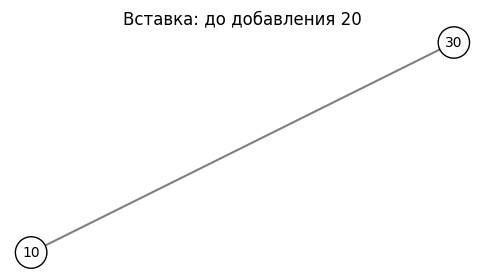

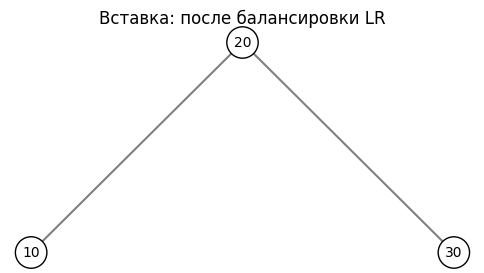

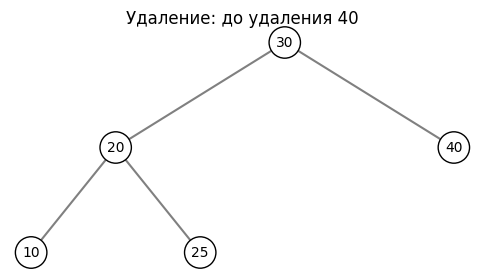

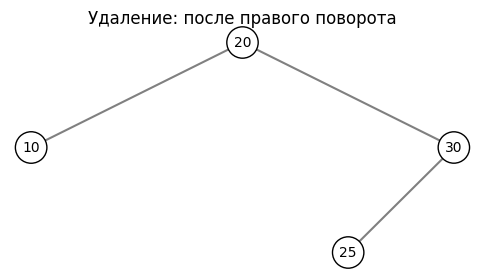

In [3]:
import matplotlib.pyplot as plt


def draw_tree(root, title):
    fig, ax = plt.subplots(figsize=(6, 3))

    def draw(node, x, y, step):
        if node is None:
            return

        for child, shift in [(node.left, -step), (node.right, step)]:
            if child:
                ax.plot([x, x + shift], [y, y - 1], color='gray')
                draw(child, x + shift, y - 1, step / 2)

        ax.text(x, y, str(node.value), ha='center', va='center',
                bbox=dict(boxstyle='circle,pad=0.5', fc='white', ec='black'))

    draw(root, 0, 0, 2)
    ax.set_title(title)
    ax.axis('off')
    plt.show()


lr_tree = AVL()
for value in [30, 10]:
    lr_tree.insert(value)
draw_tree(lr_tree.root, 'Вставка: до добавления 20')

lr_tree.insert(20)
draw_tree(lr_tree.root, 'Вставка: после балансировки LR')

delete_tree = AVL()
for value in [30, 20, 40, 10, 25]:
    delete_tree.insert(value)
draw_tree(delete_tree.root, 'Удаление: до удаления 40')

delete_tree.delete(40)
draw_tree(delete_tree.root, 'Удаление: после правого поворота')


# Тесты

Проверим:
- пустое дерево и дерево из одного узла;
- поиск существующих и отсутствующих значений;
- все четыре типа поворотов при вставке;
- дубликаты, отрицательные значения и `0`;
- удаление листа, узла с одним ребёнком и узла с двумя детьми;
- удаление корня, отсутствующего значения и балансировку после удаления;
- последовательную вставку и удаление большого числа элементов.

Вспомогательная проверка `check` рекурсивно убеждается, что значения удовлетворяют правилу BST, высоты сохранены правильно и разница высот каждого узла не больше единицы.


In [4]:
import unittest


class TestAVL(unittest.TestCase):
    def build(self, values):
        tree = AVL()
        for value in values:
            tree.insert(value)
        return tree

    def check(self, node, low=None, high=None):
        if node is None:
            return 0

        if low is not None:
            self.assertGreater(node.value, low)
        if high is not None:
            self.assertLess(node.value, high)

        left = self.check(node.left, low, node.value)
        right = self.check(node.right, node.value, high)
        self.assertEqual(node.height, 1 + max(left, right))
        self.assertLessEqual(abs(left - right), 1)
        return node.height

    def test_empty(self):
        tree = AVL()
        self.assertFalse(tree.search(5))
        tree.delete(5)
        self.assertIsNone(tree.root)

    def test_one_element(self):
        tree = self.build([7])
        self.assertTrue(tree.search(7))
        self.assertFalse(tree.search(8))
        self.check(tree.root)
        tree.delete(7)
        self.assertIsNone(tree.root)

    def test_four_rotations(self):
        for values in ([30, 20, 10], [10, 20, 30],
                       [30, 10, 20], [10, 30, 20]):
            with self.subTest(values=values):
                tree = self.build(values)
                self.assertEqual(tree.root.value, 20)
                self.assertEqual(tree.root.left.value, 10)
                self.assertEqual(tree.root.right.value, 30)
                self.check(tree.root)

    def test_search_and_negative_values(self):
        tree = self.build([5, 0, -3, 8, 12, 7])
        for value in [5, 0, -3, 8, 12, 7]:
            self.assertTrue(tree.search(value))
        for value in [-10, 1, 100]:
            self.assertFalse(tree.search(value))
        self.check(tree.root)

    def test_duplicates(self):
        tree = self.build([5, 5, 3, 3, 7, 7])
        self.assertEqual(tree.root.value, 5)
        self.assertEqual(tree.root.height, 2)
        self.check(tree.root)

    def test_delete_leaf(self):
        tree = self.build([20, 10, 30])
        tree.delete(10)
        self.assertFalse(tree.search(10))
        self.check(tree.root)

    def test_delete_one_child(self):
        tree = self.build([20, 10, 30, 25])
        tree.delete(30)
        self.assertEqual(tree.root.right.value, 25)
        self.assertFalse(tree.search(30))
        self.check(tree.root)

    def test_delete_two_children(self):
        tree = self.build([20, 10, 30, 25, 40])
        tree.delete(20)
        self.assertEqual(tree.root.value, 25)
        self.assertFalse(tree.search(20))
        self.check(tree.root)

    def test_delete_with_rotation(self):
        tree = self.build([30, 20, 40, 10, 25])
        tree.delete(40)
        self.assertEqual(tree.root.value, 20)
        self.assertFalse(tree.search(40))
        self.check(tree.root)

    def test_delete_missing_and_root(self):
        tree = self.build([2, 1, 3])
        tree.delete(100)
        self.assertTrue(tree.search(2))
        tree.delete(2)
        self.assertFalse(tree.search(2))
        self.check(tree.root)

    def test_many_operations(self):
        tree = self.build(range(100))
        self.check(tree.root)

        for value in range(0, 100, 2):
            tree.delete(value)
            self.check(tree.root)

        for value in range(100):
            self.assertEqual(tree.search(value), value % 2 == 1)


_ = unittest.main(argv=[''], exit=False)


.

.

.

.

.

.

... (2 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 11 tests in 0.010s

OK
